In [3]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [4]:
df = pd.read_csv("../data/simulation_results2.csv")
df.head()

,sim,model_knowledge,w,perf,baseline_reward,avg_reward,stake
0,0,0.0,0.00,0.148438,4.84375,4.992188,<bound method IndexOpsMixin.to_numpy of 0 ...
1,0,0.0,0.01,0.296875,4.84375,5.140625,<bound method IndexOpsMixin.to_numpy of 0 ...
2,0,0.0,0.02,0.187500,4.84375,5.031250,<bound method IndexOpsMixin.to_numpy of 0 ...
3,0,0.0,0.03,0.035156,4.84375,4.878906,<bound method IndexOpsMixin.to_numpy of 0 ...
4,0,0.0,0.04,0.000000,4.84375,4.843750,<bound method IndexOpsMixin.to_numpy of 0 ...


In [3]:
df_plot = (
    df.groupby(["model_knowledge", "w"], as_index=False)["perf"].mean()
)
df_plot

,model_knowledge,w,perf
0,0.0,0.00,0.106270
1,0.0,0.01,-0.019551
2,0.0,0.02,0.004082
3,0.0,0.03,0.073574
4,0.0,0.04,0.066699
...,...,...,...
10196,1.0,0.96,0.455801
10197,1.0,0.97,0.311543
10198,1.0,0.98,0.504941
10199,1.0,0.99,0.508340


In [9]:
df_plot = (
    df.groupby(["model_knowledge", "w"], as_index=False)["perf"]
      .mean()
      .assign(
          model_knowledge=lambda d: d["model_knowledge"].round(2),
          w=lambda d: d["w"].round(2)
      )
)
df_plot.head()

,model_knowledge,w,perf
0,0.0,0.00,0.106270
1,0.0,0.01,-0.019551
2,0.0,0.02,0.004082
3,0.0,0.03,0.073574
4,0.0,0.04,0.066699


In [5]:
matrix = df_plot.pivot(index="model_knowledge", columns="w", values="perf")
matrix.head()

w,0.00,0.01,0.02,0.03,0.04,0.05,0.06,0.07,0.08,0.09,...,0.91,0.92,0.93,0.94,0.95,0.96,0.97,0.98,0.99,1.00
model_knowledge,,,,,,,,,,,,,,,,,,,,,
0.00,0.106270,-0.019551,0.004082,0.073574,0.066699,-0.017402,0.044004,-0.027715,0.060098,-0.051191,...,-1.139004,-1.164434,-1.101973,-1.123301,-1.105566,-1.078809,-1.092832,-1.075996,-1.043652,-1.032793
0.01,0.140176,0.027051,0.122051,0.123691,0.053574,0.068691,0.038184,0.072246,0.042637,-0.070566,...,-1.200762,-1.095840,-1.154941,-1.164199,-1.174785,-1.172793,-1.133535,-1.040723,-0.988066,-0.993691
0.02,0.010527,0.151543,0.077402,0.145684,0.011816,0.125879,0.019160,-0.053301,-0.051035,0.000801,...,-1.131582,-1.120527,-1.139824,-1.134277,-1.110176,-1.056465,-1.153145,-1.091230,-0.964082,-1.018574
0.03,0.134902,0.001387,0.116582,0.087480,-0.070957,0.048262,0.043379,-0.042441,-0.041504,0.011387,...,-1.071504,-1.170566,-1.111895,-1.142363,-1.189746,-1.140059,-1.086191,-1.020098,-1.065410,-0.848965
0.04,0.124434,0.054980,-0.019512,0.061543,0.009004,-0.034668,0.006895,-0.028926,-0.027949,0.048418,...,-1.103105,-1.195137,-1.211230,-1.118496,-1.083535,-1.154043,-1.136270,-1.021543,-1.087051,-1.029746


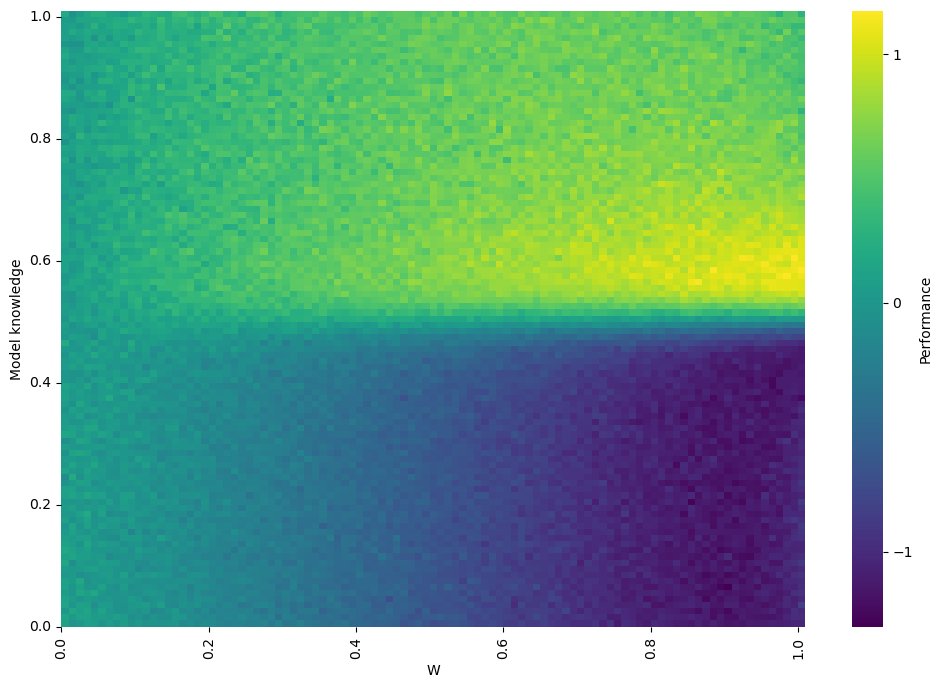

In [8]:
plt.figure(figsize=(12, 8))

sns.heatmap(matrix, cmap="viridis", annot=False, cbar_kws={"label": "Performance", "ticks": [-1., 0.0, 1.]})

# plt.contour(matrix.values, levels=[0], colors="black", linewidths=1)
# plt.axhline(y=50, color="red", linestyle="--", linewidth=2)

plt.gca().invert_yaxis()
plt.ylabel("Model knowledge")
plt.xlabel("W")

# Use the actual index and columns
plt.yticks(
    np.arange(0, len(matrix.index), 20),   # positions
    matrix.index[::20]                     # labels
)
plt.xticks(
    np.arange(0, len(matrix.columns), 20),  # positions
    matrix.columns[::20]                    # labels
)

plt.show()
